# PROYECTO 1 · Predicción de cancelaciones hoteleras
**Especialización en Ciencia de Datos e IA | Metodología CRISP-DM | Versión integrada**

> **Pregunta de negocio:** ¿Qué características *conocidas al momento de realizar una reserva* permiten estimar el riesgo de que termine cancelada o que el huésped no se presente?

**Punto central:** cada fila representa una **reserva**, no un cliente único. El proyecto predice el riesgo de la reserva, no una probabilidad permanente de una persona.

**Cómo usarlo:** ejecutar de arriba abajo en Google Colab o Jupyter. Al llegar a la celda de carga, mantener `hotel_bookings.csv` en la misma carpeta o subirlo cuando el programa lo solicite. Este notebook **no modifica el CSV original**.

**Versión de trabajo de equipo:** combina el EDA y la documentación ampliada de `Trabajo.ipynb` con los modelos sencillos, las restricciones temporales y la explicación de `Proyecto_1_CRISP_DM_Cancelaciones_Hoteleras.ipynb`. Los resultados se recalculan directamente desde el CSV.

**Límite de las evidencias:** las técnicas principales aquí usadas son Pandas, Matplotlib, Seaborn y Scikit-learn (regresión logística, árbol de decisión, métricas, división de datos y pipelines). No se incluyen Optuna, SHAP ni otros métodos avanzados que no hemos acreditado como autorizados en las clases.

## Resumen ejecutivo · Resultados comprobados
**Fuente:** `hotel_bookings.csv` (119.390 reservas; 44.224 canceladas o *No-Show*, 37,04 %). El notebook conserva los datos originales y explica cada paso.

| Resultado del experimento principal | Valor |
|---|---:|
| Modelo elegido **solo con validación** | Árbol de decisión |
| Umbral elegido en validación | 0,35 |
| Exactitud de prueba | **63,77 %** |
| AUC-ROC de prueba | **0,752** |
| F1 de prueba | **0,630** |
| Recall de prueba | **83,34 %** |
| Precisión de prueba | **50,66 %** |
| Falsas alertas en prueba | **7.178** |
| Cancelaciones no detectadas en prueba | **1.474** |

**Lectura del resultado:** encontramos la mayoría de las cancelaciones, pero aproximadamente la mitad de las reservas alertadas **no** terminó cancelada. La exactitud es apenas superior a la referencia que siempre pronostica «no cancelada» (62,96 %): por eso es fundamental mirar sensibilidad y precisión, no solo exactitud.

**Dos pruebas de sensibilidad:** al evaluar con llegadas en 2017, el modelo seleccionado usando solo 2015–2016 obtuvo AUC-ROC **0,679** y F1 **0,611**. Al eliminar únicamente las 31.994 filas exactamente idénticas, la muestra cambia a 87.396 reservas (prevalencia 27,49 %) y el modelo de ese escenario alcanza AUC-ROC **0,721** y F1 **0,534**. Son experimentos con poblaciones diferentes: **no** permiten demostrar que una regla de eliminación sea correcta.

**Alcance:** el CSV no ofrece una fotografía auditable de cada variable al crear la reserva. La predicción es un **ejercicio académico**; no constituye un sistema listo para utilizar en producción.

# 1. Comprensión del negocio
### 1.1. Problema y decisión que queremos apoyar
Las cancelaciones reducen la certeza sobre la ocupación hotelera y pueden dificultar la planeación comercial. Se busca **identificar reservas de mayor riesgo desde su creación** para priorizar contactos o confirmaciones, no para penalizar automáticamente a huéspedes.

### 1.2. Objetivo general
Construir y evaluar un modelo básico de **clasificación supervisada binaria** para estimar la probabilidad de que una reserva termine cancelada o en no presentación, a partir de características que, razonablemente, se conocen al reservar.

### 1.3. Objetivos específicos
1. Describir reservas, cancelaciones y calidad del CSV original.
2. Explorar relaciones de la cancelación con anticipación, hotel, segmento, historial y otras dimensiones.
3. Preparar datos **sin utilizar información posterior a la creación de la reserva**.
4. Comparar una referencia simple, regresión logística y árbol de decisión con datos de validación.
5. Evaluar el modelo seleccionado en un conjunto de prueba no utilizado para elegirlo.
6. Examinar limitaciones mediante pruebas temporales y un escenario alternativo sin filas idénticas.
7. Explicar los resultados, riesgos y una propuesta de uso académico.

### 1.4. Cómo juzgaremos el resultado
- **Recall/sensibilidad:** proporción de reservas que efectivamente se cancelan y que el modelo detecta.
- **Precisión:** qué proporción de las reservas señaladas como riesgosas realmente se cancela.
- **F1:** equilibrio entre las dos anteriores; lo usaremos para **elegir modelo y umbral en validación**.
- **AUC-ROC:** capacidad de ordenar reservas de mayor a menor riesgo sin fijar un umbral.
- **Matriz de confusión:** falsos positivos y falsos negativos. Sin costos operativos disponibles, no podemos asegurar que el umbral de mejor F1 sea el más rentable para un hotel.

# 2. Comprensión de los datos y EDA
## 2.1. Entorno y lectura del CSV
**Qué hacemos:** importamos las librerías usadas en clase, fijamos una semilla para repetir los resultados y cargamos la fuente original sin modificarla.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

SEMILLA = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 35)

ruta = Path("hotel_bookings.csv")
if not ruta.exists():
    try:
        from google.colab import files
        print("Sube el archivo 'hotel_bookings.csv' para iniciar.")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Ubica hotel_bookings.csv en la misma carpeta del notebook.")
assert ruta.exists(), "No se encontró el archivo hotel_bookings.csv"
df = pd.read_csv(ruta)
print("Filas:", len(df), "| Variables:", df.shape[1])
display(df.head(3))

Filas: 119390 | Variables: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


**Interpretación:** una fila es una observación de reserva; varios registros pueden tener atributos idénticos sin representar necesariamente una duplicación errónea. No hay una clave inequívoca de reserva o de huésped.

In [2]:
print("Tipos de variables:")
display(pd.DataFrame({"Tipo": df.dtypes.astype(str),
                      "Nulos": df.isna().sum(),
                      "Valores diferentes": df.nunique(dropna=False)}))
print("Resumen numérico (columnas más útiles para el problema):")
cols_describe = ["lead_time", "adr", "stays_in_weekend_nights", "stays_in_week_nights",
                 "adults", "children", "babies", "previous_cancellations", "total_of_special_requests"]
display(df[cols_describe].describe().T.round(2))

Tipos de variables:


,Tipo,Nulos,Valores diferentes
hotel,object,0,2
is_canceled,int64,0,2
lead_time,int64,0,479
arrival_date_year,int64,0,3
arrival_date_month,object,0,12
arrival_date_week_number,int64,0,53
arrival_date_day_of_month,int64,0,31
stays_in_weekend_nights,int64,0,17
stays_in_week_nights,int64,0,35
adults,int64,0,14


Resumen numérico (columnas más útiles para el problema):


,count,mean,std,min,25%,50%,75%,max
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
adr,119390.0,101.83,50.54,-6.38,69.29,94.58,126.0,5400.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0
previous_cancellations,119390.0,0.09,0.84,0.00,0.00,0.00,0.0,26.0
total_of_special_requests,119390.0,0.57,0.79,0.00,0.00,0.00,1.0,5.0


## 2.2. Calidad, consistencia y definición del target
**Qué hacemos:** contamos faltantes, filas idénticas y registros sospechosos; sin corregirlos todavía. Revisamos que `is_canceled` concuerde con el resultado registrado.

In [3]:
nulos = df.isna().sum().loc[lambda x: x > 0].sort_values(ascending=False)
tabla_nulos = pd.DataFrame({"Faltantes": nulos,
                             "Porcentaje (%)": (100 * nulos / len(df)).round(2)})
display(tabla_nulos)

repetidas = int(df.duplicated().sum())
sin_huespedes = int(((df.adults + df.children.fillna(0) + df.babies) == 0).sum())
sin_noches = int(((df.stays_in_weekend_nights + df.stays_in_week_nights) == 0).sum())
print(f"Filas exactamente iguales a otra: {repetidas:,} ({repetidas/len(df):.2%})")
print("Filas sin huéspedes registrados:", sin_huespedes)
print("Filas sin noches de estadía:", sin_noches)
print("Tarifas diarias negativas:", int((df.adr < 0).sum()))
print("Tarifas diarias mayores a 1.000:", int((df.adr > 1000).sum()))

display(pd.crosstab(df["reservation_status"], df["is_canceled"], margins=True))
assert df.is_canceled.isin([0, 1]).all(), "Target con valores inesperados"
assert len(df) == 119390 and df.shape[1] == 32, "Verifica que cargaste el archivo esperado"

,Faltantes,Porcentaje (%)
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


Filas exactamente iguales a otra: 31,994 (26.80%)
Filas sin huéspedes registrados: 180
Filas sin noches de estadía: 715
Tarifas diarias negativas: 1
Tarifas diarias mayores a 1.000: 1


is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


**Interpretación y decisión:** `is_canceled=1` incluye `Canceled` **y** `No-Show`; no equivale exclusivamente a cancelaciones explícitas. `company` está mayoritariamente vacío y `agent` tiene muchos faltantes, pero no podemos asumir automáticamente que un dato faltante equivale a «no aplica». Los registros idénticos **no se borran de la muestra principal**. Las tarifas extremas se documentan; `adr` no se utilizará en el modelo principal, por lo que no es necesario imputarla para predecir.

## 2.3. Anticipación, duración y tarifa: distribución univariada
**Qué hacemos:** observamos las formas y los valores extremos de tres variables numéricas relevantes. El histograma de `adr` limita el eje visual a valores de 0 a 500, pero **no elimina registros del CSV**.

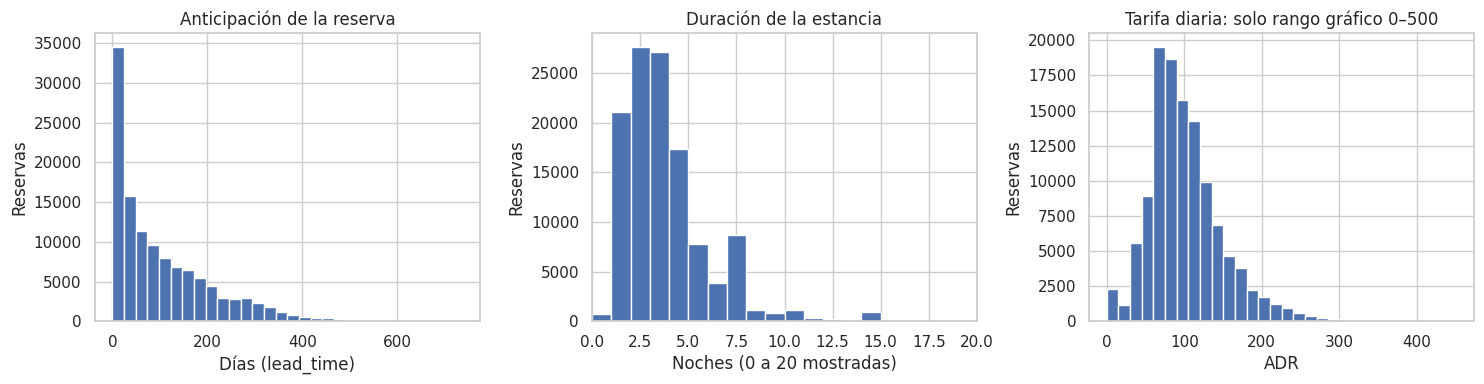

Anticipación (media / mediana): 104.01 / 69.0
Tarifa diaria (mín. / mediana / máx.): -6.38 / 94.575 / 5400.0


In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].hist(df["lead_time"], bins=30)
ejes[0].set(title="Anticipación de la reserva", xlabel="Días (lead_time)", ylabel="Reservas")
noches = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
ejes[1].hist(noches, bins=range(0, 22))
ejes[1].set(title="Duración de la estancia", xlabel="Noches (0 a 20 mostradas)", ylabel="Reservas", xlim=(0, 20))
ejes[2].hist(df.loc[df.adr.between(0, 500), "adr"], bins=30)
ejes[2].set(title="Tarifa diaria: solo rango gráfico 0–500", xlabel="ADR", ylabel="Reservas")
plt.tight_layout(); plt.show()
print("Anticipación (media / mediana):", round(df.lead_time.mean(), 2), "/", df.lead_time.median())
print("Tarifa diaria (mín. / mediana / máx.):", df.adr.min(), "/", df.adr.median(), "/", df.adr.max())

**Interpretación:** una media mayor que la mediana de `lead_time` sugiere una cola hacia reservas con mayor anticipación. Las tarifas extremas merecen investigación de calidad; un valor llamativo no demuestra por sí solo que sea erróneo.

## 2.4. Distribución de la variable objetivo
**Qué hacemos:** comparamos cantidades y proporciones de reservas que terminaron canceladas o en *No-Show*.

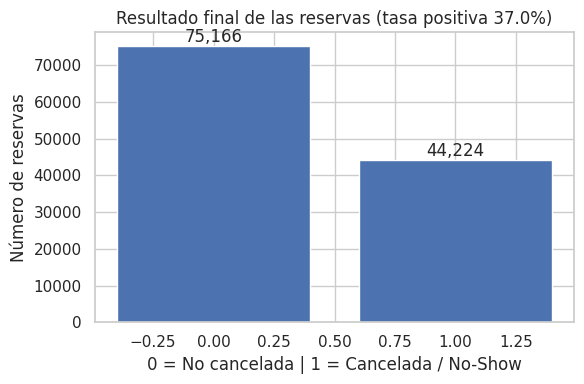

Tasa de resultado positivo: 37.04%


In [5]:
conteo_target = df.is_canceled.value_counts().sort_index()
tasa_general = float(df.is_canceled.mean())
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([0, 1], [conteo_target[0], conteo_target[1]])
ax.set(title=f"Resultado final de las reservas (tasa positiva {tasa_general:.1%})",
       xlabel="0 = No cancelada | 1 = Cancelada / No-Show", ylabel="Número de reservas")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout(); plt.show()
print("Tasa de resultado positivo:", f"{tasa_general:.2%}")

**Interpretación:** la clase positiva es minoritaria. Un modelo que siempre predice «no cancelada» ya tendría una exactitud aparentemente aceptable; por eso reportamos también sensibilidad, precisión, F1 y AUC-ROC.

## 2.5. Relaciones con la cancelación: anticipación y tipo de hotel
**Qué hacemos:** calculamos **tasas dentro de cada grupo** en lugar de confundir volumen con riesgo. Los intervalos de anticipación se crean para el EDA; el modelo utilizará `lead_time` original.

,Reservas,Canceladas,Tasa (%)
rango_anticipacion,,,
0–7,19746,1902,9.63
8–30,18960,5283,27.86
31–90,29553,11141,37.70
91–180,26439,11821,44.71
181–365,21544,11947,55.45
366+,3148,2130,67.66


,Reservas,Canceladas,Tasa (%)
hotel,,,
City Hotel,79330,33102,41.73
Resort Hotel,40060,11122,27.76


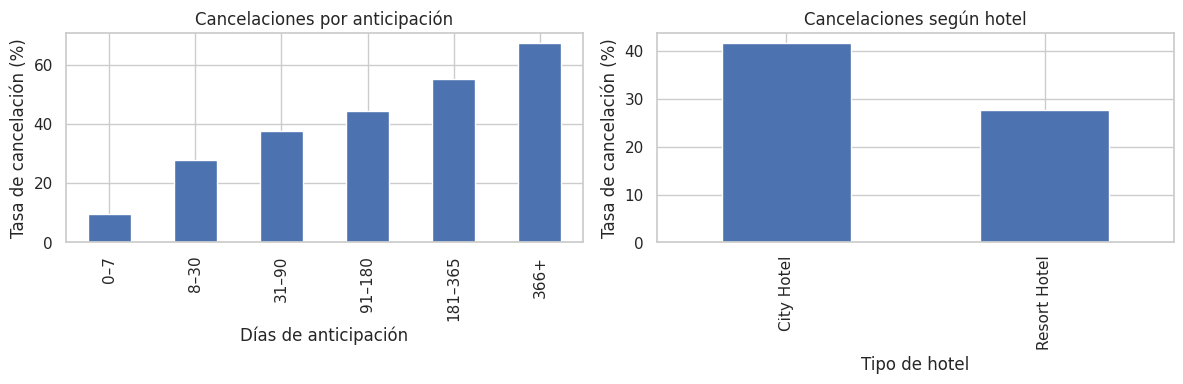

In [6]:
bins = [-1, 7, 30, 90, 180, 365, float("inf")]
labels = ["0–7", "8–30", "31–90", "91–180", "181–365", "366+"]
df_eda = df.copy()
df_eda["rango_anticipacion"] = pd.cut(df_eda.lead_time, bins=bins, labels=labels)

def tabla_tasas(columna, datos=df_eda):
    tabla = (datos.groupby(columna, observed=True)["is_canceled"]
             .agg(Reservas="size", Canceladas="sum", Tasa="mean"))
    tabla["Tasa (%)"] = (100 * tabla.pop("Tasa")).round(2)
    return tabla

t_ant = tabla_tasas("rango_anticipacion")
t_hotel = tabla_tasas("hotel")
display(t_ant)
display(t_hotel)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
t_ant["Tasa (%)"].plot(kind="bar", ax=ejes[0])
ejes[0].set(title="Cancelaciones por anticipación", xlabel="Días de anticipación", ylabel="Tasa de cancelación (%)")
t_hotel["Tasa (%)"].plot(kind="bar", ax=ejes[1])
ejes[1].set(title="Cancelaciones según hotel", xlabel="Tipo de hotel", ylabel="Tasa de cancelación (%)")
plt.tight_layout(); plt.show()

**Interpretación:** la tasa de cancelación sube desde aproximadamente **9,6 %** en reservas con 0–7 días de anticipación hasta cerca de **67,7 %** en las de más de 365 días. En el **City Hotel**, la tasa es **41,7 %**, frente a **27,8 %** en Resort Hotel. Esto describe asociaciones: no demuestra que anticipar o elegir un hotel sea la causa de la cancelación.

## 2.6. Relación con segmento comercial, recurrencia y tipo de cliente
**Qué hacemos:** analizamos dimensiones comerciales, tomando en cuenta cuántas reservas hay en cada grupo.

Variable: market_segment


,Reservas,Canceladas,Tasa (%)
market_segment,,,
Online TA,56477,20739,36.72
Offline TA/TO,24219,8311,34.32
Groups,19811,12097,61.06
Direct,12606,1934,15.34
Corporate,5295,992,18.73
Complementary,743,97,13.06
Aviation,237,52,21.94
Undefined,2,2,100.00


Variable: distribution_channel


,Reservas,Canceladas,Tasa (%)
distribution_channel,,,
TA/TO,97870,40152,41.03
Direct,14645,2557,17.46
Corporate,6677,1474,22.08
GDS,193,37,19.17
Undefined,5,4,80.00


Variable: customer_type


,Reservas,Canceladas,Tasa (%)
customer_type,,,
Transient,89613,36514,40.75
Transient-Party,25124,6389,25.43
Contract,4076,1262,30.96
Group,577,59,10.23


Variable: is_repeated_guest


,Reservas,Canceladas,Tasa (%)
is_repeated_guest,,,
0,115580,43672,37.79
1,3810,552,14.49


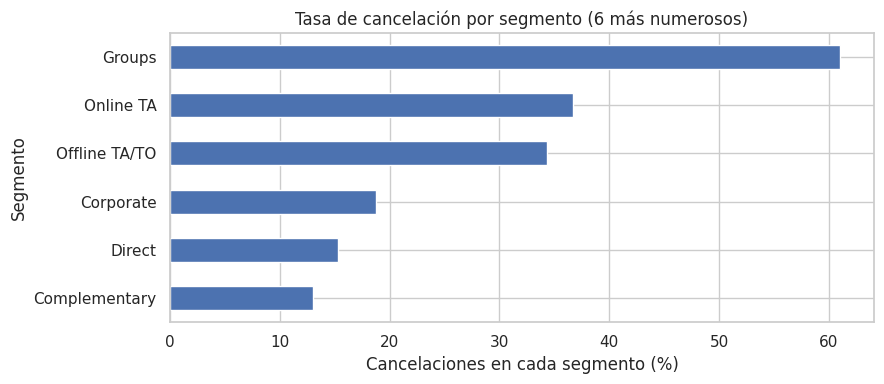

In [7]:
for variable in ["market_segment", "distribution_channel", "customer_type", "is_repeated_guest"]:
    print("Variable:", variable)
    display(tabla_tasas(variable).sort_values("Reservas", ascending=False).head(10))

segmentos = tabla_tasas("market_segment").sort_values("Reservas", ascending=False).head(6)
fig, ax = plt.subplots(figsize=(9, 4))
segmentos["Tasa (%)"].sort_values().plot(kind="barh", ax=ax)
ax.set(title="Tasa de cancelación por segmento (6 más numerosos)",
       xlabel="Cancelaciones en cada segmento (%)", ylabel="Segmento")
plt.tight_layout(); plt.show()

**Interpretación:** el segmento **Groups** presenta aproximadamente **61,1 %** de cancelaciones, frente a **15,3 %** del segmento **Direct**. Las reservas de huéspedes recurrentes presentan **14,5 %** frente a **37,8 %** entre no recurrentes. Son diferencias descriptivas; puede haber influencia de otras características como la anticipación y el hotel.

## 2.7. Historial, solicitudes y depósito: señales que exigen cautela
**Qué hacemos:** exploramos asociaciones del historial de cancelaciones y de solicitudes especiales. También observamos la variable depósito, **solo como contexto**, porque no está acreditado que refleje el estado inicial de la reserva.

Variable: tiene_cancelacion_previa


,Reservas,Canceladas,Tasa (%)
tiene_cancelacion_previa,,,
No,112906,38282,33.91
Sí,6484,5942,91.64


Variable: total_of_special_requests


,Reservas,Canceladas,Tasa (%)
total_of_special_requests,,,
0,70318,33556,47.72
1,33226,7318,22.02
2,12969,2866,22.10
3,2497,446,17.86
4,340,36,10.59
5,40,2,5.00


Variable: deposit_type


,Reservas,Canceladas,Tasa (%)
deposit_type,,,
No Deposit,104641,29694,28.38
Non Refund,14587,14494,99.36
Refundable,162,36,22.22


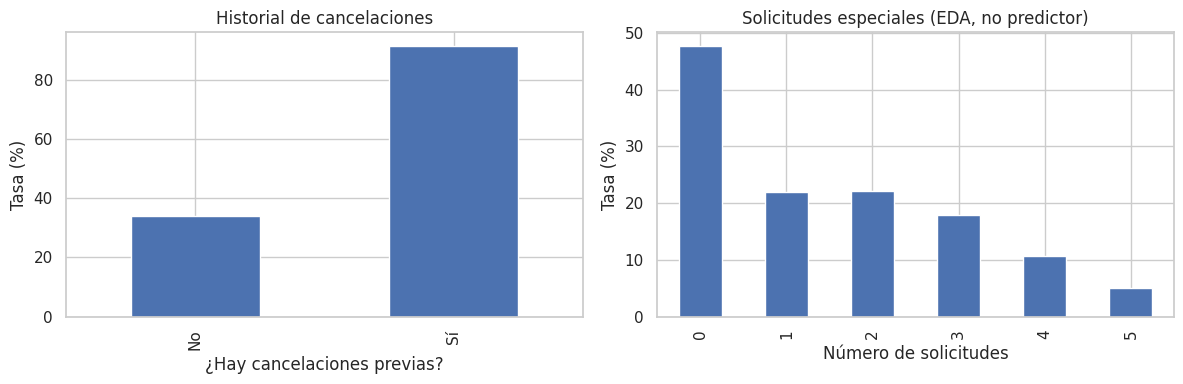

In [8]:
df_eda["tiene_cancelacion_previa"] = (df_eda.previous_cancellations > 0).map({False: "No", True: "Sí"})
for variable in ["tiene_cancelacion_previa", "total_of_special_requests", "deposit_type"]:
    print("Variable:", variable)
    display(tabla_tasas(variable).sort_values("Reservas", ascending=False).head(10))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
tabla_tasas("tiene_cancelacion_previa")["Tasa (%)"].plot(kind="bar", ax=ejes[0])
ejes[0].set(title="Historial de cancelaciones", xlabel="¿Hay cancelaciones previas?", ylabel="Tasa (%)")
tabla_tasas("total_of_special_requests")["Tasa (%)"].plot(kind="bar", ax=ejes[1])
ejes[1].set(title="Solicitudes especiales (EDA, no predictor)", xlabel="Número de solicitudes", ylabel="Tasa (%)")
plt.tight_layout(); plt.show()

**Interpretación:** un historial de cancelaciones anteriores puede ser útil si fue construido con hechos previos a la reserva. El número de solicitudes especiales y el depósito muestran asociaciones muy fuertes (en `Non Refund`, casi **99,4 %**), pero **no entran al modelo**: el dataset no demuestra que sus valores sean los de la fecha de creación. No hay fundamento para interpretar ese 99,4 % como efecto causal de una política no reembolsable.

## 2.8. País de origen y tendencias temporales
**Qué hacemos:** analizamos `country` y la evolución mensual de tasas, pero no usamos país como predictor principal porque su disponibilidad en la creación de la reserva no está demostrada. La cobertura de 2015 y 2017 es parcial.

,Reservas,Canceladas,Tasa (%)
country_eda,,,
PRT,48590,27519,56.64
GBR,12129,2453,20.22
FRA,10415,1934,18.57
ESP,8568,2177,25.41
DEU,7287,1218,16.71
ITA,3766,1333,35.40
IRL,3375,832,24.65
BEL,2342,474,20.24


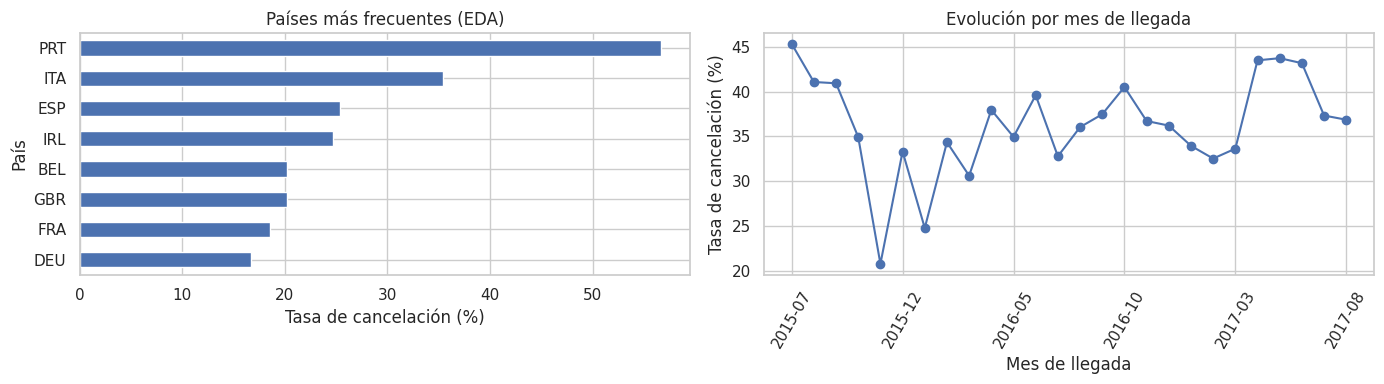

Primera llegada: 2015-07-01 | Última: 2017-08-31


In [9]:
df_eda["country_eda"] = df_eda["country"].fillna("Sin dato")
paises = df_eda["country_eda"].value_counts().head(8).index
t_paises = tabla_tasas("country_eda").loc[paises]
display(t_paises)

fecha_llegada = pd.to_datetime(
    df.arrival_date_year.astype(str) + "-" + df.arrival_date_month + "-" +
    df.arrival_date_day_of_month.astype(str), format="%Y-%B-%d", errors="coerce")
assert fecha_llegada.notna().all(), "Hay fechas de llegada inválidas"
df_eda["mes_llegada"] = fecha_llegada.dt.to_period("M").astype(str)
serie_mes = df_eda.groupby("mes_llegada")["is_canceled"].agg(Reservas="size", Tasa="mean")

fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
t_paises["Tasa (%)"].sort_values().plot(kind="barh", ax=ejes[0])
ejes[0].set(title="Países más frecuentes (EDA)", xlabel="Tasa de cancelación (%)", ylabel="País")
(serie_mes.Tasa * 100).plot(kind="line", marker="o", ax=ejes[1])
ejes[1].tick_params(axis="x", rotation=60)
ejes[1].set(title="Evolución por mes de llegada", xlabel="Mes de llegada", ylabel="Tasa de cancelación (%)")
plt.tight_layout(); plt.show()
print("Primera llegada:", fecha_llegada.min().date(), "| Última:", fecha_llegada.max().date())

**Interpretación:** los cambios mensuales son descriptivos y no prueban cambios causales de comportamiento. **2015 solo contiene julio–diciembre y 2017 enero–agosto**, por lo que la comparación de años completos estaría sesgada por periodos diferentes.

## 2.9. Correlaciones numéricas
**Qué hacemos:** calculamos correlaciones de Pearson, vistas en clase, solo entre variables numéricas interpretables. Identificadores como `agent` o `company` **no deben tratarse como magnitudes continuas**.

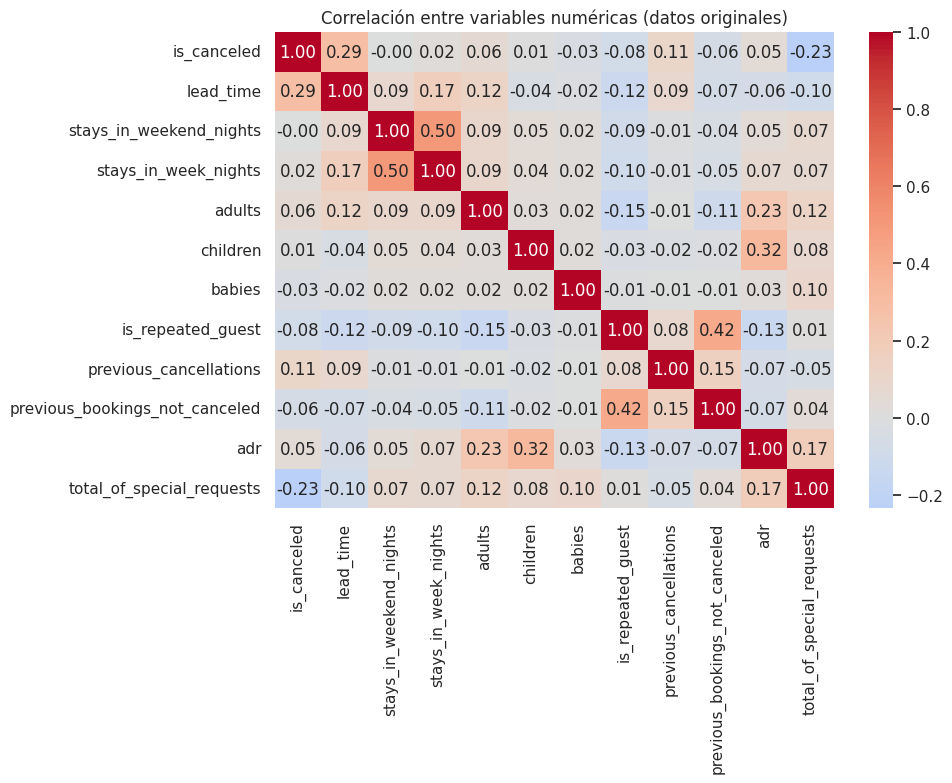

,Correlación con target
lead_time,0.293
previous_cancellations,0.110
adults,0.060
adr,0.048
stays_in_week_nights,0.025
children,0.005
stays_in_weekend_nights,-0.002
babies,-0.032
previous_bookings_not_canceled,-0.057
is_repeated_guest,-0.085


In [10]:
columnas_corr = ["is_canceled", "lead_time", "stays_in_weekend_nights",
                  "stays_in_week_nights", "adults", "children", "babies",
                  "is_repeated_guest", "previous_cancellations",
                  "previous_bookings_not_canceled", "adr", "total_of_special_requests"]
correlacion = df[columnas_corr].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlacion, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Correlación entre variables numéricas (datos originales)")
plt.tight_layout(); plt.show()
display(correlacion["is_canceled"].drop("is_canceled").sort_values(ascending=False).to_frame("Correlación con target").round(3))

### Conclusiones de comprensión de datos
- `lead_time` y algunos atributos comerciales muestran asociaciones con `is_canceled`.
- Las relaciones no son causales y las correlaciones numéricas no sustituyen una evaluación predictiva.
- Hay faltantes, filas idénticas, reservas sin huéspedes o noches y valores extremos; **no se deben corregir por intuición**.
- El target reúne cancelaciones y *No-Show*.
- **Prohibición metodológica:** `reservation_status` y `reservation_status_date` revelan el desenlace; `assigned_room_type`, `booking_changes` y otras variables actualizadas posteriormente no deben entrar al modelo de predicción al crear la reserva.

Pasamos a preparación sin eliminar registros ni redefinir el target.

# 3. Preparación de los datos
## 3.1. Política de selección de variables
Se mantienen **15 variables** razonablemente asociadas a condiciones iniciales, comparables a las del primer cuaderno:

| Grupo | Variables | Justificación |
|---|---|---|
| Tiempo | `lead_time`, `arrival_date_month` | Anticipación y mes previsto de llegada |
| Estancia | `hotel`, `stays_in_weekend_nights`, `stays_in_week_nights`, `reserved_room_type`, `meal` | Condiciones solicitadas |
| Huéspedes | `adults`, `children`, `babies` | Composición registrada |
| Canal | `market_segment`, `distribution_channel` | Canal/segmento inicial esperado |
| Historial | `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled` | Antecedentes que **deberían ser previos** a la reserva |

**Excluimos por temporalidad o ambigüedad:** `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes`, `days_in_waiting_list`, `deposit_type`, `adr`, `total_of_special_requests`, `required_car_parking_spaces`, `country`, `agent`, `company`, `customer_type` y el año de llegada como predictor. No estamos afirmando que todos los excluidos sean inútiles: solo que no se garantiza su valor en el instante deseado.

**Limitación importante:** este archivo no trae la captura exacta del instante de creación. Incluso algunos atributos seleccionados podrían haberse editado con posterioridad; el análisis sigue siendo un **prototipo académico** y no una verificación de ausencia total de fuga temporal.

**Decisiones de calidad:** mantenemos duplicados y registros inusuales en el escenario principal; los nulos en `children` se completan con la mediana aprendida **solo del entrenamiento**. Las categorías se codifican con el mismo criterio, también aprendido en entrenamiento.

In [11]:
columnas_num = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
                "adults", "children", "babies", "is_repeated_guest",
                "previous_cancellations", "previous_bookings_not_canceled"]
columnas_cat = ["hotel", "arrival_date_month", "meal", "market_segment",
                "distribution_channel", "reserved_room_type"]
columnas_modelo = columnas_num + columnas_cat
columnas_no_validas = ["reservation_status", "reservation_status_date", "assigned_room_type",
                       "booking_changes", "days_in_waiting_list", "deposit_type", "adr",
                       "total_of_special_requests", "required_car_parking_spaces", "country",
                       "agent", "company", "customer_type", "arrival_date_year"]
assert not set(columnas_modelo) & set(columnas_no_validas)
assert len(columnas_modelo) == 15
X = df[columnas_modelo].copy()
y = df["is_canceled"].copy()
print("Variables para el modelo:", len(columnas_modelo))
print("Valores faltantes entre los predictores:", int(X.isna().sum().sum()))
print("Filas conservadas:", len(X))
print("La fuente original no ha sido modificada:", len(df) == 119390)

Variables para el modelo: 15
Valores faltantes entre los predictores: 4
Filas conservadas: 119390
La fuente original no ha sido modificada: True


## 3.2. Partición entrenamiento / validación / prueba
**Qué hacemos:** separamos la muestra **antes de calcular medianas, estandarizar o codificar categorías**. La prueba final (20 %) se aparta y **no se usa** para seleccionar variables, modelo ni umbral.

- Entrenamiento: 60 % (se ajustan los modelos y preprocesamiento).
- Validación: 20 % (se elige el modelo y umbral).
- Prueba final: 20 % (se mide una única vez el resultado elegido).

La semilla fija permite reproducir las mismas divisiones.

In [12]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=SEMILLA, stratify=y_temp)
print("Entrenamiento:", X_train.shape, "| positivos:", f"{y_train.mean():.2%}")
print("Validación:", X_val.shape, "| positivos:", f"{y_val.mean():.2%}")
print("Prueba final:", X_test.shape, "| positivos:", f"{y_test.mean():.2%}")
assert len(X_train) + len(X_val) + len(X_test) == len(df)
assert not set(X_train.index) & set(X_val.index)
assert not set(X_train.index) & set(X_test.index)
assert not set(X_val.index) & set(X_test.index)

Entrenamiento: (71634, 15) | positivos: 37.04%
Validación: (23878, 15) | positivos: 37.04%
Prueba final: (23878, 15) | positivos: 37.04%


## 3.3. Preparación dentro de un pipeline
**Por qué:** un *pipeline* permite aplicar en el orden correcto imputación, transformación y modelo, **aprendiendo cada transformación solo con entrenamiento**.

- Numéricas: mediana para nulos y estandarización (útil para regresión logística).
- Categóricas: valor más frecuente para nulos y columnas 0/1 (*one-hot*).
- Categorías nuevas en validación o prueba: se ignoran de forma controlada, sin recalcular las categorías con los datos de prueba.

In [13]:
def crear_pipeline(tipo):
    prep_num = Pipeline([
        ("mediana", SimpleImputer(strategy="median")),
        ("escala", StandardScaler())
    ])
    prep_cat = Pipeline([
        ("moda", SimpleImputer(strategy="most_frequent")),
        ("columnas_01", OneHotEncoder(handle_unknown="ignore"))
    ])
    preparador = ColumnTransformer([
        ("numericas", prep_num, columnas_num),
        ("categoricas", prep_cat, columnas_cat)
    ])
    if tipo == "Regresión logística":
        modelo = LogisticRegression(max_iter=1000, random_state=SEMILLA)
    elif tipo == "Árbol de decisión":
        modelo = DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, random_state=SEMILLA)
    else:
        raise ValueError("Tipo de modelo no contemplado en clase")
    return Pipeline([("preparacion", preparador), ("modelo", modelo)])

modelos = ["Regresión logística", "Árbol de decisión"]
print("Modelos listos:", modelos)

Modelos listos: ['Regresión logística', 'Árbol de decisión']


# 4. Modelado
## 4.1. Entrenar modelos y establecer una referencia
**Qué hacemos:** ajustamos ambos modelos exclusivamente con entrenamiento y miramos sus probabilidades en validación. La referencia sin aprendizaje siempre dice «no cancelada», para mostrar por qué la exactitud aislada puede engañar.

In [14]:
def obtener_metricas(nombre, reales, probas, umbral=0.50):
    predichas = (np.asarray(probas) >= umbral).astype(int)
    return {"Modelo": nombre,
            "Exactitud": accuracy_score(reales, predichas),
            "Precisión": precision_score(reales, predichas, zero_division=0),
            "Recall": recall_score(reales, predichas, zero_division=0),
            "F1": f1_score(reales, predichas, zero_division=0),
            "AUC-ROC": roc_auc_score(reales, probas)}

modelos_entrenados = {}
prob_val = {}
for nombre in modelos:
    pipeline = crear_pipeline(nombre)
    pipeline.fit(X_train, y_train)
    modelos_entrenados[nombre] = pipeline
    prob_val[nombre] = pipeline.predict_proba(X_val)[:, 1]

base_val = np.zeros(len(y_val), dtype=int)
referencia_val = {
    "Modelo": "Siempre no cancelada",
    "Exactitud": accuracy_score(y_val, base_val),
    "Precisión": 0.0, "Recall": 0.0, "F1": 0.0, "AUC-ROC": 0.5
}
comparacion_val_05 = pd.DataFrame([referencia_val] + [
    obtener_metricas(nombre, y_val, prob_val[nombre]) for nombre in modelos
])
print("Resultados de VALIDACIÓN con umbral 0,50:")
display(comparacion_val_05.round(3))

Resultados de VALIDACIÓN con umbral 0,50:


,Modelo,Exactitud,Precisión,Recall,F1,AUC-ROC
0,Siempre no cancelada,0.630,0.000,0.000,0.000,0.500
1,Regresión logística,0.709,0.705,0.366,0.482,0.737
2,Árbol de decisión,0.711,0.747,0.334,0.462,0.748


**Interpretación:** comparamos calidad con datos que no entrenaron el modelo. La referencia ayuda a ver si el modelo detecta cancelaciones en lugar de acertar siempre la clase más común.

## 4.2. Seleccionar el umbral sin tocar el test
La salida del modelo es una probabilidad. Para decidir «riesgo alto», necesitamos un umbral. Probamos umbrales sencillos de 0,20 a 0,70, **solo en validación**. Para este ejercicio elegimos la combinación modelo + umbral que obtiene mayor **F1 de validación**; no estamos optimizando ingresos porque faltan costos reales.

,Modelo,Umbral,Precisión,Recall,F1,AUC-ROC
14,Árbol de decisión,0.35,0.504,0.832,0.628,0.748
2,Regresión logística,0.30,0.490,0.787,0.604,0.737


Seleccionado SOLO con validación: Árbol de decisión, umbral 0.35


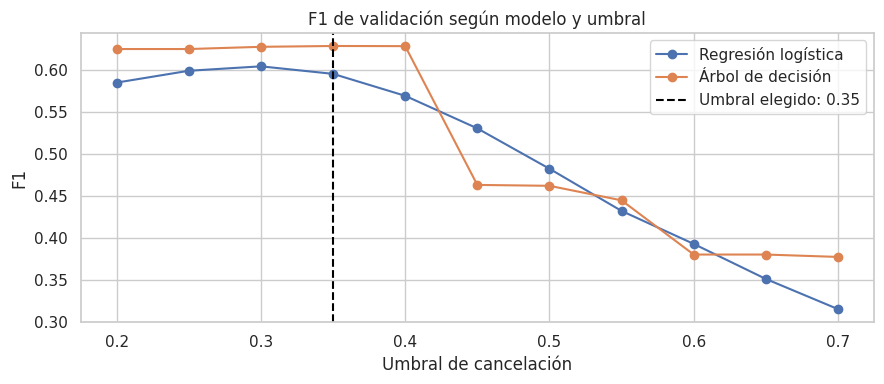

In [15]:
umbrales = np.arange(0.20, 0.701, 0.05)
filas_validacion = []
for nombre in modelos:
    for t in umbrales:
        m = obtener_metricas(nombre, y_val, prob_val[nombre], t)
        filas_validacion.append({"Modelo": nombre, "Umbral": round(float(t), 2), **{
            "Precisión": m["Precisión"], "Recall": m["Recall"],
            "F1": m["F1"], "AUC-ROC": m["AUC-ROC"]}})
resultados_validacion = pd.DataFrame(filas_validacion)
mejores_por_modelo = (resultados_validacion.sort_values(
    ["F1", "Modelo", "Umbral"], ascending=[False, True, True]
).drop_duplicates("Modelo"))
display(mejores_por_modelo.round(3))

mejor_fila = resultados_validacion.sort_values(
    ["F1", "Modelo", "Umbral"], ascending=[False, True, True]
).iloc[0]
modelo_elegido = mejor_fila["Modelo"]
umbral_elegido = float(mejor_fila["Umbral"])
print(f"Seleccionado SOLO con validación: {modelo_elegido}, umbral {umbral_elegido:.2f}")

fig, ax = plt.subplots(figsize=(9, 4))
for nombre in modelos:
    tabla = resultados_validacion[resultados_validacion.Modelo == nombre]
    ax.plot(tabla.Umbral, tabla.F1, marker="o", label=nombre)
ax.axvline(umbral_elegido, linestyle="--", color="black", label=f"Umbral elegido: {umbral_elegido:.2f}")
ax.set(title="F1 de validación según modelo y umbral", xlabel="Umbral de cancelación", ylabel="F1")
ax.legend()
plt.tight_layout(); plt.show()

**Decisión:** modelo y umbral quedaron definidos **antes de observar el resultado del test**. El hecho de que F1 sea máximo en validación no asegura que ese sea el mejor umbral para una operación real.

# 5. Evaluación
## 5.1. Prueba final independiente
**Qué hacemos:** aplicamos el modelo y el umbral ya elegidos al 20 % que se había reservado. No cambiaremos la elección a partir de su rendimiento.

Modelo final seleccionado en validación: Árbol de decisión
Umbral fijado en validación: 0.35
Exactitud de referencia (siempre 0): 0.63


,Modelo,Exactitud,Precisión,Recall,F1,AUC-ROC
0,Árbol de decisión,0.6377,0.5066,0.8334,0.6302,0.7521


TN=7,855 | FP=7,178 | FN=1,474 | TP=7,371


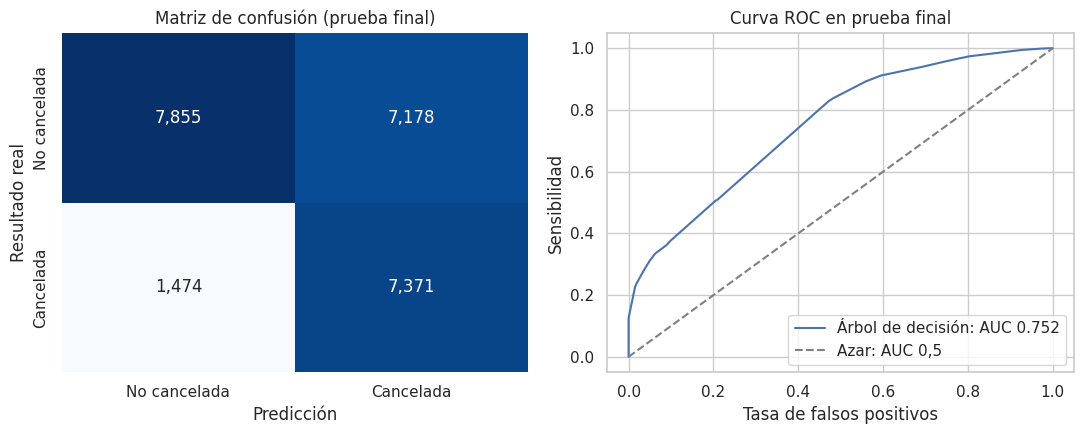

In [16]:
modelo_final = modelos_entrenados[modelo_elegido]
proba_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= umbral_elegido).astype(int)
resultado_test = obtener_metricas(modelo_elegido, y_test, proba_test, umbral_elegido)
baseline_test = accuracy_score(y_test, np.zeros(len(y_test), dtype=int))
print("Modelo final seleccionado en validación:", modelo_elegido)
print("Umbral fijado en validación:", umbral_elegido)
print("Exactitud de referencia (siempre 0):", round(baseline_test, 3))
display(pd.DataFrame([resultado_test]).round(4))

matriz = confusion_matrix(y_test, pred_test, labels=[0, 1])
tn, fp, fn, tp = matriz.ravel()
print(f"TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}")
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(matriz, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ejes[0],
            xticklabels=["No cancelada", "Cancelada"],
            yticklabels=["No cancelada", "Cancelada"])
ejes[0].set(title="Matriz de confusión (prueba final)", xlabel="Predicción", ylabel="Resultado real")
fpr, tpr, _ = roc_curve(y_test, proba_test)
ejes[1].plot(fpr, tpr, label=f"{modelo_elegido}: AUC {resultado_test['AUC-ROC']:.3f}")
ejes[1].plot([0,1],[0,1],"--", color="gray", label="Azar: AUC 0,5")
ejes[1].set(title="Curva ROC en prueba final", xlabel="Tasa de falsos positivos", ylabel="Sensibilidad")
ejes[1].legend()
plt.tight_layout(); plt.show()

**Interpretación:** TP = cancelaciones detectadas; FN = cancelaciones no anticipadas; FP = alertas sobre reservas que no se cancelaron. La conveniencia de aceptar más FP para reducir FN depende de costos y capacidad de atención, datos que no están disponibles en el CSV.

## 5.2. Priorización: reservas con mayor riesgo
**Qué hacemos:** ordenamos las reservas del test por probabilidad estimada. Si un equipo pudiera revisar solo el 10 % con mayor puntuación, calculamos cuántas cancelaciones concentraría ese grupo. Es un diagnóstico **retrospectivo**, no una intervención demostrada.

Top 10 % de riesgo: 2,388 reservas
Tasa observada de cancelación en el top 10 %: 88.19%
Fracción de cancelaciones del test capturadas allí: 23.81%
Tasa general del test: 37.04%


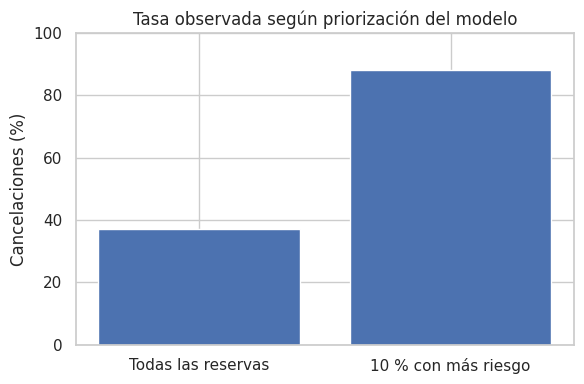

In [17]:
ranking = pd.DataFrame({"Probabilidad estimada": proba_test, "Canceló": np.asarray(y_test)})
ranking = ranking.sort_values("Probabilidad estimada", ascending=False).reset_index(drop=True)
n_prioridad = int(np.ceil(0.10 * len(ranking)))
prioridad = ranking.head(n_prioridad)
tasa_top10 = float(prioridad["Canceló"].mean())
porcentaje_capturado = float(prioridad["Canceló"].sum() / y_test.sum())
print(f"Top 10 % de riesgo: {n_prioridad:,} reservas")
print(f"Tasa observada de cancelación en el top 10 %: {tasa_top10:.2%}")
print(f"Fracción de cancelaciones del test capturadas allí: {porcentaje_capturado:.2%}")
print(f"Tasa general del test: {y_test.mean():.2%}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Todas las reservas", "10 % con más riesgo"],
       [100*y_test.mean(), 100*tasa_top10])
ax.set(title="Tasa observada según priorización del modelo", ylabel="Cancelaciones (%)", ylim=(0, 100))
plt.tight_layout(); plt.show()

## 5.3. Interpretación sencilla de las variables
**Qué hacemos:** describimos las variables con mayor peso en el modelo escogido, sin confundir asociación con causa. Para regresión logística se muestran coeficientes de columnas codificadas (no se deben interpretar como importancias causales); para árbol, importancia en las divisiones.

Importancia de variables en el árbol:


,Coeficiente o importancia
numericas__lead_time,0.337
numericas__previous_cancellations,0.336
categoricas__market_segment_Groups,0.072
numericas__previous_bookings_not_canceled,0.056
categoricas__market_segment_Online TA,0.049
categoricas__hotel_Resort Hotel,0.041
categoricas__hotel_City Hotel,0.031
categoricas__distribution_channel_Direct,0.018
numericas__adults,0.016
categoricas__meal_HB,0.016


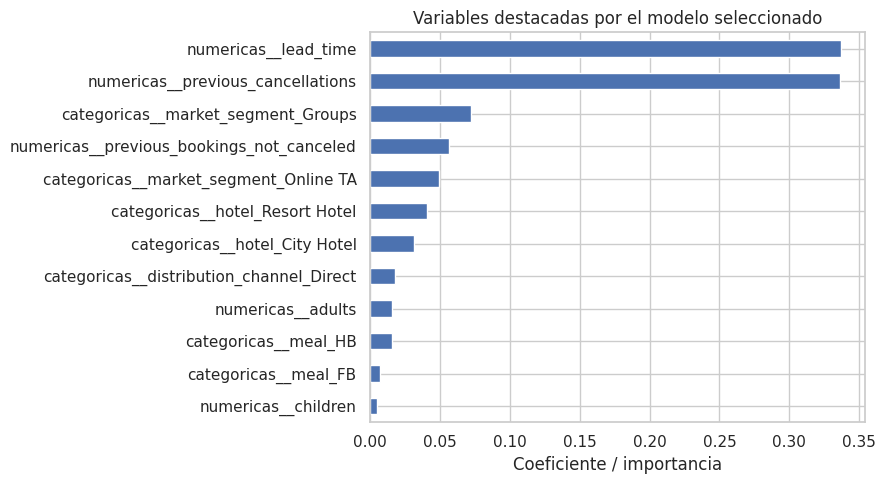

In [18]:
nombres_transformados = modelo_final.named_steps["preparacion"].get_feature_names_out()
modelo_interno = modelo_final.named_steps["modelo"]
if modelo_elegido == "Regresión logística":
    valores = pd.Series(modelo_interno.coef_[0], index=nombres_transformados)
    importantes = valores.reindex(valores.abs().sort_values(ascending=False).head(12).index)
    print("Coeficientes de mayor magnitud (signo condicionado al resto de variables):")
else:
    valores = pd.Series(modelo_interno.feature_importances_, index=nombres_transformados)
    importantes = valores.sort_values(ascending=False).head(12)
    print("Importancia de variables en el árbol:")
display(importantes.round(3).to_frame("Coeficiente o importancia"))
fig, ax = plt.subplots(figsize=(9, 5))
importantes.sort_values().plot(kind="barh", ax=ax)
ax.set(title="Variables destacadas por el modelo seleccionado", xlabel="Coeficiente / importancia")
plt.tight_layout(); plt.show()

**Advertencia de interpretación:** con one-hot, los coeficientes de una categoría dependen de las demás columnas y de la codificación; un signo no demuestra que cambiar esa característica cambie la conducta del huésped. Los gráficos bivariados ayudan a explicar los patrones, pero no constituyen efectos causales.

# 6. Comprobaciones de robustez
## 6.1. ¿Qué pasa si evaluamos con llegadas posteriores?
**Qué hacemos:** usamos únicamente reservas de llegada prevista en **2015–2016** para aprender y elegir modelo/umbral; reservamos las de **2017** para comprobar el rendimiento en otro periodo. **No utilizamos 2017 durante la selección.**

Es una comprobación adicional, no equivalente a un experimento real de predicción al reservar. La fecha de llegada no siempre coincide con la fecha de creación y 2017 está incompleto.

In [19]:
mask_antes = df.arrival_date_year <= 2016
X_pasado = X.loc[mask_antes]
y_pasado = y.loc[mask_antes]
X_futuro = X.loc[~mask_antes]
y_futuro = y.loc[~mask_antes]
Xp_train, Xp_val, yp_train, yp_val = train_test_split(
    X_pasado, y_pasado, test_size=0.25, random_state=SEMILLA, stratify=y_pasado)

filas_pasado = []
modelos_pasado = {}
for nombre in modelos:
    p = crear_pipeline(nombre).fit(Xp_train, yp_train)
    modelos_pasado[nombre] = p
    pv = p.predict_proba(Xp_val)[:, 1]
    for t in umbrales:
        m = obtener_metricas(nombre, yp_val, pv, t)
        filas_pasado.append({"Modelo": nombre, "Umbral": round(float(t), 2), "F1": m["F1"]})
mejor_pasado = pd.DataFrame(filas_pasado).sort_values(
    ["F1", "Modelo", "Umbral"], ascending=[False, True, True]).iloc[0]
nombre_pasado, umbral_pasado = mejor_pasado["Modelo"], float(mejor_pasado["Umbral"])
proba_2017 = modelos_pasado[nombre_pasado].predict_proba(X_futuro)[:, 1]
resultado_2017 = obtener_metricas(nombre_pasado, y_futuro, proba_2017, umbral_pasado)
print("Solo datos de 2015–2016 para elegir:", len(X_pasado),
      "| Reservas de llegada en 2017:", len(X_futuro))
print("Modelo y umbral elegidos SIN consultar 2017:", nombre_pasado, umbral_pasado)
display(pd.DataFrame([resultado_2017]).round(4))
print("Comparar con evaluación aleatoria exige cautela: cambió el periodo, la muestra y el entrenamiento.")

Solo datos de 2015–2016 para elegir: 78703 | Reservas de llegada en 2017: 40687
Modelo y umbral elegidos SIN consultar 2017: Árbol de decisión 0.35


,Modelo,Exactitud,Precisión,Recall,F1,AUC-ROC
0,Árbol de decisión,0.6071,0.4953,0.7986,0.6114,0.6789


Comparar con evaluación aleatoria exige cautela: cambió el periodo, la muestra y el entrenamiento.


**Interpretación:** una caída en el rendimiento entre la prueba aleatoria y 2017 sería compatible con diferencias entre periodos. No prueba por sí sola *drift* causal ni asegura el comportamiento futuro: 2015 y 2017 están parcialmente cubiertos.

## 6.2. ¿Qué pasa si eliminamos filas completamente idénticas?
**Qué hacemos:** creamos un segundo escenario, **sin sobrescribir el CSV ni alterar la evaluación principal**, para observar cómo cambian la tasa del target y el resultado. En ese escenario repetimos entrenamiento, validación, elección y prueba. **No son poblaciones idénticas:** comparar métricas no demuestra cuál representación es la verdadera.

In [20]:
df_sin_identicas = df.drop_duplicates().copy()
X_sin = df_sin_identicas[columnas_modelo]
y_sin = df_sin_identicas.is_canceled
print("Población principal:", len(df), "| prevalencia:", f"{y.mean():.2%}")
print("Población sin filas idénticas:", len(df_sin_identicas),
      "| prevalencia:", f"{y_sin.mean():.2%}")

Xtemp_s, Xtest_s, ytemp_s, ytest_s = train_test_split(
    X_sin, y_sin, test_size=0.2, stratify=y_sin, random_state=SEMILLA)
Xtrain_s, Xval_s, ytrain_s, yval_s = train_test_split(
    Xtemp_s, ytemp_s, test_size=0.25, stratify=ytemp_s, random_state=SEMILLA)

r_s = []
p_s = {}
for nombre in modelos:
    ps = crear_pipeline(nombre).fit(Xtrain_s, ytrain_s)
    p_s[nombre] = ps
    prob_s = ps.predict_proba(Xval_s)[:, 1]
    for t in umbrales:
        r_s.append({"Modelo": nombre, "Umbral": round(float(t),2),
                    "F1": f1_score(yval_s, prob_s >= t)})
sel_s = pd.DataFrame(r_s).sort_values(
    ["F1", "Modelo", "Umbral"], ascending=[False, True, True]).iloc[0]
nombre_s, umbral_s = sel_s.Modelo, float(sel_s.Umbral)
predproba_s = p_s[nombre_s].predict_proba(Xtest_s)[:, 1]
resultado_sin = obtener_metricas(nombre_s, ytest_s, predproba_s, umbral_s)
print("Modelo y umbral seleccionados con validación del escenario alternativo:", nombre_s, umbral_s)
display(pd.DataFrame([resultado_sin]).round(4))
comparacion_escenarios = pd.DataFrame([
    {"Escenario": "Con todas las filas", "Reservas": len(df), "Prevalencia": y.mean(),
     "Modelo": modelo_elegido, "Umbral": umbral_elegido, "F1": resultado_test["F1"],
     "AUC-ROC": resultado_test["AUC-ROC"]},
    {"Escenario": "Sin filas idénticas", "Reservas": len(df_sin_identicas), "Prevalencia": y_sin.mean(),
     "Modelo": nombre_s, "Umbral": umbral_s, "F1": resultado_sin["F1"],
     "AUC-ROC": resultado_sin["AUC-ROC"]}
])
display(comparacion_escenarios.round(3))

Población principal: 119390 | prevalencia: 37.04%
Población sin filas idénticas: 87396 | prevalencia: 27.49%


Modelo y umbral seleccionados con validación del escenario alternativo: Árbol de decisión 0.25


,Modelo,Exactitud,Precisión,Recall,F1,AUC-ROC
0,Árbol de decisión,0.6377,0.413,0.7548,0.5339,0.7206


,Escenario,Reservas,Prevalencia,Modelo,Umbral,F1,AUC-ROC
0,Con todas las filas,119390,0.370,Árbol de decisión,0.35,0.630,0.752
1,Sin filas idénticas,87396,0.275,Árbol de decisión,0.25,0.534,0.721


**Decisión:** no elegiremos el escenario con mayor AUC por ese único motivo. Quitar filas idénticas puede eliminar observaciones reales y cambiar la composición de segmentos y del target. En esta comparación eliminamos **solo** las 31.994 filas idénticas; por eso quedan **87.396**, no las **87.230** del cuaderno del compañero, que además había eliminado 166 registros sin huéspedes. Para resolver qué registros eliminar harían falta identificadores de reserva originales o confirmación de la fuente hotelera.

## 6.3. ¿Cuántas reservas de prueba comparten exactamente los mismos predictores con entrenamiento?
**Qué hacemos:** verificamos coincidencia de perfiles de las **15 variables de entrada** entre entrenamiento y prueba. Esta coincidencia no demuestra error de duplicación, pero alerta de que una partición aleatoria podría resultar más fácil si existen muchos perfiles repetidos.

In [21]:
firma_train = pd.util.hash_pandas_object(X_train, index=False).to_numpy()
firma_test = pd.util.hash_pandas_object(X_test, index=False).to_numpy()
solapadas = np.isin(firma_test, np.unique(firma_train))
print(f"Reservas de prueba con perfil de predictores repetido en train: {solapadas.sum():,} / {len(solapadas):,} ({solapadas.mean():.2%})")
print("Esto se refiere a los predictores, NO identifica huéspedes ni prueba duplicación errónea.")

Reservas de prueba con perfil de predictores repetido en train: 10,861 / 23,878 (45.49%)
Esto se refiere a los predictores, NO identifica huéspedes ni prueba duplicación errónea.


# 7. Conclusiones y propuesta de uso
## 7.1. Resumen numérico reproducible
Se imprimen las métricas del archivo ejecutado, no cifras copiadas de otro notebook. Las conclusiones combinan la predicción con sus límites de negocio.

In [22]:
print("=" * 65)
print("RESUMEN DEL PROYECTO")
print("=" * 65)
print(f"Reservas originales: {len(df):,}; resultados positivos: {int(y.sum()):,} ({y.mean():.2%})")
print(f"Reservas idénticas adicionales: {repetidas:,}; escenario sin idénticas: {len(df_sin_identicas):,}")
print(f"Modelo final validado: {modelo_elegido}; umbral: {umbral_elegido:.2f}")
print(f"Prueba aleatoria | AUC-ROC: {resultado_test['AUC-ROC']:.3f} | F1: {resultado_test['F1']:.3f} | Recall: {resultado_test['Recall']:.3f} | Precisión: {resultado_test['Precisión']:.3f}")
print(f"2017 sin usar ese año para elegir | Modelo: {nombre_pasado} | AUC-ROC: {resultado_2017['AUC-ROC']:.3f} | F1: {resultado_2017['F1']:.3f}")
print(f"Sin filas idénticas | Modelo: {nombre_s} | AUC-ROC: {resultado_sin['AUC-ROC']:.3f} | F1: {resultado_sin['F1']:.3f}")
print(f"Tasa cancelación en 10% más riesgoso de test: {tasa_top10:.2%}")
print("=" * 65)

RESUMEN DEL PROYECTO
Reservas originales: 119,390; resultados positivos: 44,224 (37.04%)
Reservas idénticas adicionales: 31,994; escenario sin idénticas: 87,396
Modelo final validado: Árbol de decisión; umbral: 0.35
Prueba aleatoria | AUC-ROC: 0.752 | F1: 0.630 | Recall: 0.833 | Precisión: 0.507
2017 sin usar ese año para elegir | Modelo: Árbol de decisión | AUC-ROC: 0.679 | F1: 0.611
Sin filas idénticas | Modelo: Árbol de decisión | AUC-ROC: 0.721 | F1: 0.534
Tasa cancelación en 10% más riesgoso de test: 88.19%


## 7.2. Conclusiones de negocio
1. El EDA mostró asociaciones destacadas entre cancelación y anticipación, tipo de hotel, segmento comercial y antecedentes. **No son pruebas de causalidad**.
2. El árbol de decisión seleccionado detectó **83,3 %** de los resultados positivos de prueba (**7.371** aciertos), pero generó **7.178 falsas alertas** y dejó sin detectar **1.474**. El F1 fue **0,630** y AUC-ROC **0,752**.
3. El modelo y su umbral fueron elegidos **exclusivamente con validación**. La prueba final se consultó solo después de fijarlos.
4. Al eliminar filas idénticas cambian notablemente prevalencia y resultados; también cae AUC-ROC al evaluar con llegadas de 2017. No hay evidencia para declarar que uno de los escenarios representa mejor la realidad.
5. El 10 % de las reservas con puntuación más alta en test concentró una **tasa observada de 88,2 %**; la puntuación del árbol, sin verificación de calibración, **no debe interpretarse como una probabilidad individual exacta**.
6. El archivo no permite reconstruir de forma completamente confiable todas las características **en la fecha de creación**. Esto impide afirmar que el rendimiento sea directamente trasladable a un hotel actual.

## 7.3. Uso propuesto (no implementado)
Una posible aplicación, una vez validados los datos en un sistema hotelero real, sería ordenar reservas nuevas según puntuación de riesgo y **priorizar confirmaciones voluntarias o seguimiento** de las de mayor riesgo. Habría que definir costo de contacto, presupuesto, respeto al huésped y resultados de una prueba piloto. No recomendamos negar reservas automáticamente.

## 7.4. Qué entregar y cómo exponerlo
- **Código:** este cuaderno ejecutable, con el CSV original sin modificar.
- **Documentación:** problema, definiciones, decisiones de exclusión, EDA, modelos, métricas, sensibilidad y limitaciones.
- **GitHub:** publicar el notebook y un README que explique cómo ejecutarlo.
- **Presentación (20 min + 5 de preguntas):** problema (2), datos/calidad (3), EDA (5), preparación y modelos (4), evaluación/robustez (4), conclusiones (2).

## 7.5. Fuentes y alcance
- `hotel_bookings.csv`: fuente de las 119.390 reservas; analizada sin modificarla.
- `Trabajo.ipynb`: aportes del equipo, especialmente EDA ampliado y sensibilidad a duplicados.
- `Proyecto_1_CRISP_DM_Cancelaciones_Hoteleras.ipynb`: CRISP-DM, modelos básicos y restricciones temporales.
- Las seis grabaciones suministradas orientan el nivel de las técnicas; no se presupone autorización para Optuna, SHAP u otras técnicas avanzadas.

**Límites adicionales:** no hay identificadores únicos para distinguir reservas repetidas ni cifras de pérdida económica, ni fotografía histórica exacta al reservar. Los modelos fueron entrenados con registros históricos de 2015–2017 y **no se han desplegado**.